In [1]:
!pip install -q monai torch torchvision nibabel SimpleITK matplotlib
import monai
import torch

print("Setup Complete:")
print(f" - PyTorch Version: {torch.__version__}")
print(f" - CUDA Available:  {torch.cuda.is_available()}")
if torch.cuda.is_available():
  print(f" - Active GPU:     {torch.cuda.get_device_name(0)}")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 33.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 19.2 MB/s eta 0:00:00
Setup Complete:
 - PyTorch Version: 2.11.0+cu128
 - CUDA Available:  True
 - Active GPU:     Tesla T4


In [2]:
import glob
import os
import matplotlib.pyplot as plt
from monai.data import DataLoader, Dataset
from monai.transforms import (
    Compose,
    EnsureChannelFirstd,
    EnsureTyped,
    LoadImaged,
    NormalizeIntensityd,
    Orientationd,
    RandCropByPosNegLabeld,
    RandFlipd,
    Spacingd,
)
import nibabel as nib
import numpy as np
import torch


def load_brats_file_list(data_dir: str):
  patient_dirs = sorted([
      os.path.join(data_dir, d)
      for d in os.listdir(data_dir)
      if os.path.isdir(os.path.join(data_dir, d))
  ])
  data_list = []
  for p in patient_dirs:
    p_id = os.path.basename(p)
    t1 = glob.glob(os.path.join(p, "*t1.nii*"))
    t1ce = glob.glob(os.path.join(p, "*t1ce.nii*")) or glob.glob(
        os.path.join(p, "*t1gd.nii*")
    )
    t2 = glob.glob(os.path.join(p, "*t2.nii*"))
    flair = glob.glob(os.path.join(p, "*flair.nii*"))
    seg = glob.glob(os.path.join(p, "*seg.nii*"))
    if t1 and t1ce and t2 and flair and seg:
      data_list.append({
          "image": [t1[0], t1ce[0], t2[0], flair[0]],
          "label": seg[0],
          "patient_id": p_id,
      })
  return data_list


def get_module1_transforms(patch_size=(128, 128, 128)):
  return Compose([
      LoadImaged(keys=["image", "label"]),
      EnsureChannelFirstd(keys=["image", "label"]),
      Orientationd(keys=["image", "label"], axcodes="RAS"),
      Spacingd(
          keys=["image", "label"],
          pixdim=(1.0, 1.0, 1.0),
          mode=("bilinear", "nearest"),
      ),
      NormalizeIntensityd(keys="image", nonzero=True, channel_wise=True),
      RandCropByPosNegLabeld(
          keys=["image", "label"],
          label_key="label",
          spatial_size=patch_size,
          pos=2,
          neg=1,
          num_samples=1,
          image_key="image",
          image_threshold=0,
      ),
      RandFlipd(keys=["image", "label"], prob=0.5, spatial_axis=0),
      EnsureTyped(keys=["image", "label"], track_meta=False),
  ])


print("Pipeline functions initialized successfully.")

Pipeline functions initialized successfully.


In [3]:
# Create sample multimodal brain volumes
DATA_DIR = "./data/BraTS2021_Training_Data/BraTS2021_00001"
os.makedirs(DATA_DIR, exist_ok=True)
affine = np.eye(4)
shape = (140, 140, 140)

# Simulate 4 MRI sequences
for seq in ["t1", "t1ce", "t2", "flair"]:
  vol = (np.random.randn(*shape) * 25 + 100).astype(np.float32)
  vol[vol < 0] = 0
  nib.save(
      nib.Nifti1Image(vol, affine), f"{DATA_DIR}/BraTS2021_00001_{seq}.nii.gz"
  )

# Simulate ground truth tumor labels
mask = np.zeros(shape, dtype=np.uint8)
mask[50:85, 50:85, 50:85] = 1  # Necrotic Core
mask[40:95, 40:95, 40:95] = 2  # Edema
mask[60:80, 60:80, 60:80] = 4  # Enhancing Tumor
nib.save(nib.Nifti1Image(mask, affine), f"{DATA_DIR}/BraTS2021_00001_seg.nii.gz")

print("Created multi-sequence sample dataset in:", DATA_DIR)

Created multi-sequence sample dataset in: ./data/BraTS2021_Training_Data/BraTS2021_00001


/usr/local/lib/python3.13/dist-packages/monai/utils/deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


--- Module 1 Verification Statistics ---
Batch Image Tensor Shape (C, H, W, D): (4, 128, 128, 128)
Batch Label Tensor Shape (H, W, D):    (128, 128, 128)
Normalized Foreground Mean:            0.0000
Normalized Foreground Std:             1.0001


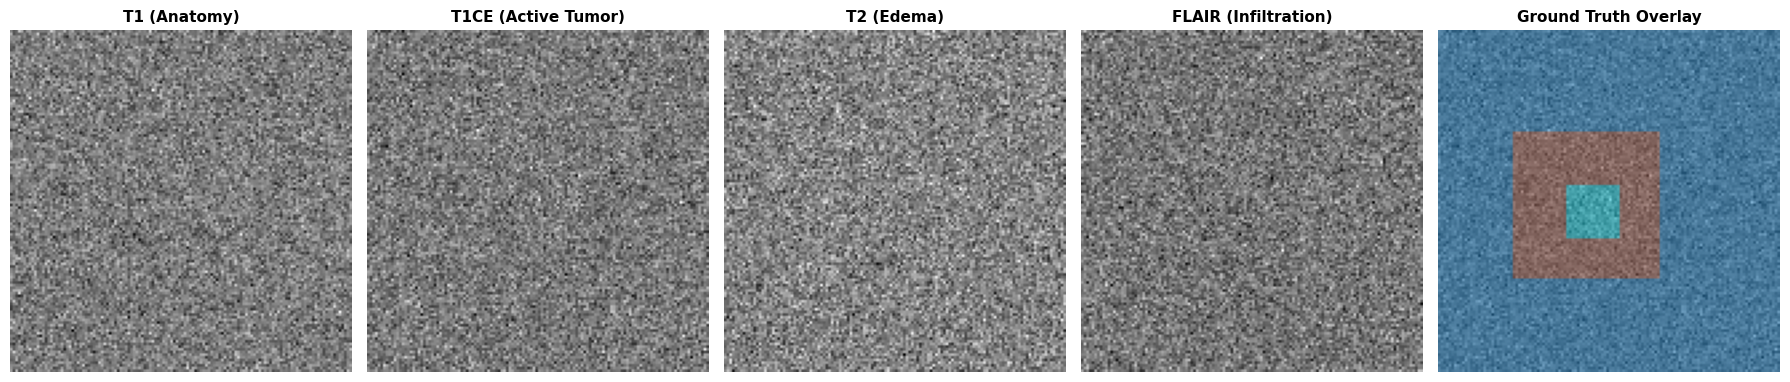

Saved verification figure to './outputs/Module_1_Verification.png'


In [4]:
# 1. Load data through MONAI pipeline
data_list = load_brats_file_list("./data/BraTS2021_Training_Data")
transforms = get_module1_transforms(patch_size=(128, 128, 128))
ds = Dataset(data=data_list, transform=transforms)
loader = DataLoader(ds, batch_size=1)

batch = next(iter(loader))
img_patch = batch["image"][0].numpy()  # Shape: (4, 128, 128, 128)
seg_patch = batch["label"][0, 0].numpy()  # Shape: (128, 128, 128)

print("--- Module 1 Verification Statistics ---")
print(f"Batch Image Tensor Shape (C, H, W, D): {img_patch.shape}")
print(f"Batch Label Tensor Shape (H, W, D):    {seg_patch.shape}")
print(
    f"Normalized Foreground Mean:           "
    f" {img_patch[img_patch != 0].mean():.4f}"
)
print(
    f"Normalized Foreground Std:            "
    f" {img_patch[img_patch != 0].std():.4f}"
)

# 2. Plot 5-Panel Slice Visual Verification
slice_z = 64  # Middle slice
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
titles = [
    "T1 (Anatomy)",
    "T1CE (Active Tumor)",
    "T2 (Edema)",
    "FLAIR (Infiltration)",
    "Ground Truth Overlay",
]

for i in range(4):
  axes[i].imshow(img_patch[i, :, :, slice_z], cmap="gray")
  axes[i].set_title(titles[i], fontsize=11, fontweight="bold")
  axes[i].axis("off")

# Overlay mask on T1CE
axes[4].imshow(img_patch[1, :, :, slice_z], cmap="gray")
axes[4].imshow(seg_patch[:, :, slice_z], cmap="tab10", alpha=0.55)
axes[4].set_title(titles[4], fontsize=11, fontweight="bold")
axes[4].axis("off")

plt.tight_layout()
os.makedirs("./outputs", exist_ok=True)
plt.savefig("./outputs/Module_1_Verification.png", dpi=300)
plt.show()
print("Saved verification figure to './outputs/Module_1_Verification.png'")